# Embeddings et scores de similarité



Dans ce notebook, vous allez utiliser le point d'accès d'embeddings de l'API Gemini pour explorer les scores de similarité.

> **Version adaptée pour Google Colab** : ce notebook est en français, lit la clé API depuis les **secrets Colab** et utilise le modèle `gemini-embedding-001` (le modèle `text-embedding-004` d'origine a été arrêté le 14 janvier 2026).

## Installer le SDK

In [ ]:
# Étape 1 : Mise à jour du SDK google-genai pour s'assurer de disposer des dernières fonctionnalités de l'API Gemini
!pip install -U -q "google-genai"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 7.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.59.0 which is incompatible.


In [ ]:
# Importation de la classe principale Client et des types de configuration depuis le nouveau SDK Google GenAI
from google import genai
from google.genai import types

# Affichage de la version installée pour validation
genai.__version__

'2.25.0'

### Politique de nouvelle tentative (retry)

En cas d'erreur 429 (quota) ou 503 (modèle surchargé), l'appel est relancé automatiquement après 2 s, 4 s, 8 s… pendant 60 s au maximum. Il n'y a aucune attente quand l'appel réussit.

> **Clé gratuite** : le tier gratuit est partagé et peut être saturé pendant le cours. Si une cellule met un peu de temps à répondre, c'est normal : laissez le retry faire son travail. Si l'erreur persiste après 60 s, relancez simplement la cellule.

In [ ]:
from google.api_core import retry

# Définition de la condition de réessai : on cible uniquement les codes d'erreur 429 (limite de requêtes) et 503 (service indisponible)
is_retriable = lambda e: (isinstance(e, genai.errors.APIError) and e.code in {429, 503})

# Configuration de la politique de retry : attente initiale de 2s, maximum 15s entre deux tentatives, pour un maximum de 60s cumulées
politique_retry = retry.Retry(predicate=is_retriable, initial=2, maximum=15, timeout=60)

# Sauvegarde de la méthode d'origine pour éviter une surcharge récursive si on réexécute la cellule
if not hasattr(genai.models.Models, "_embed_original"):
    genai.models.Models._embed_original = genai.models.Models.embed_content

# Application de la politique de retry sur la méthode d'embedding de l'API
genai.models.Models.embed_content = politique_retry(genai.models.Models._embed_original)

### Configurer votre clé API

Pour exécuter la cellule suivante, votre clé API doit être enregistrée dans un [secret Colab](https://colab.research.google.com/notebooks/secrets.ipynb) nommé `GOOGLE_API_KEY` :

1. Dans la barre latérale gauche de Colab, cliquez sur l'icône **clé** 🔑 (« Secrets »).
2. Cliquez sur **Ajouter un secret**, saisissez `GOOGLE_API_KEY` comme nom et collez votre clé comme valeur.
3. Activez l'interrupteur **Accès au notebook**.

Si vous n'avez pas encore de clé API, vous pouvez en obtenir une sur [AI Studio](https://aistudio.google.com/app/apikey). Vous trouverez des [instructions détaillées dans la documentation](https://ai.google.dev/gemini-api/docs/api-key).

Hors de Colab (exécution locale, VM…), la cellule utilise la variable d'environnement `GOOGLE_API_KEY`.

In [ ]:
import os

# Initialisation de la variable de la clé API
GOOGLE_API_KEY = None

# 1) Tentative de récupération de la clé via le gestionnaire de secrets de Google Colab
try:
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get("GOOGLE_API_KEY")
except ImportError:
    pass  # Ignoré si le script est exécuté en dehors de Colab

# 2) Alternative : récupération de la clé via les variables d'environnement système
if not GOOGLE_API_KEY:
    GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY")

# Validation : si aucune clé n'est trouvée, on lève une erreur explicite
if not GOOGLE_API_KEY:
    raise ValueError(
        "Clé API introuvable : ajoutez un secret Colab nommé GOOGLE_API_KEY "
        "et activez « Accès au notebook »."
    )

print("Clé API chargée ✅")

Clé API chargée ✅


Si vous obtenez une erreur du type `SecretNotFoundError` ou `NotebookAccessError`, vérifiez que le secret s'appelle exactement `GOOGLE_API_KEY` **et** que l'interrupteur **Accès au notebook** est activé dans le panneau Secrets (icône clé). Colab peut aussi afficher une fenêtre vous demandant d'autoriser l'accès : cliquez sur **Autoriser l'accès**.

### Explorer les modèles disponibles

Dans ce guide, vous utiliserez la méthode d'API [`embedContent`](https://ai.google.dev/api/embeddings#method:-models.embedcontent) pour calculer des embeddings par lots. Trouvez un modèle qui la prend en charge grâce au point d'accès [`models.list`](https://ai.google.dev/api/models#method:-models.list). Vous trouverez plus d'informations sur les modèles d'embedding sur [la page des modèles](https://ai.google.dev/gemini-api/docs/embeddings).

Le modèle utilisé est défini une seule fois dans la variable `EMBEDDING_MODEL` : `gemini-embedding-001`. Il accepte le paramètre `task_type` utilisé dans ce notebook et renvoie un embedding par texte.

> **Pour aller plus loin** : le modèle plus récent `gemini-embedding-2` fonctionne différemment. Il n'accepte pas `task_type` (la tâche s'indique par un préfixe dans le texte), et une liste de textes passée directement dans `contents` produit **un seul** embedding agrégé. Il faudrait donc adapter le code avant de l'utiliser.

In [ ]:
# Définition du modèle d'embedding recommandé (adapté aux tâches de similarité)
EMBEDDING_MODEL = "gemini-embedding-001"

# Initialisation du client d'API Gemini avec la clé préalablement chargée
client = genai.Client(api_key=GOOGLE_API_KEY)

# Exploration des modèles disponibles prenant en charge l'action 'embedContent'
for model in client.models.list():
  if 'embedContent' in model.supported_actions:
    print(model.name)

models/gemini-embedding-001
models/gemini-embedding-2-preview
models/gemini-embedding-2


## Calculer des scores de similarité

Cet exemple calcule les embeddings de plusieurs variantes du pangramme anglais `The quick brown fox jumps over the lazy dog` (« Le rapide renard brun saute par-dessus le chien paresseux »), avec des fautes d'orthographe et des versions raccourcies de la phrase. Un autre pangramme et une phrase sans rapport ont été ajoutés pour comparaison.

Dans cet exercice, vous allez utiliser les embeddings pour calculer des scores de similarité : le `task_type` de ces embeddings est donc `semantic_similarity`. Consultez la [référence de l'API](https://ai.google.dev/api/embeddings#v1beta.TaskType) pour la liste complète des tâches.

In [ ]:
# Liste de phrases à comparer (variations de la même phrase, un pangramme alternatif, et un texte hors-sujet)
texts = [
    'The quick brown fox jumps over the lazy dog.',
    'The quick rbown fox jumps over the lazy dog.', # Contient une faute de frappe ('rbown')
    'teh fast fox jumps over the slow woofer.',     # Version synonyme très modifiée
    'a quick brown fox jmps over lazy dog.',        # Version légèrement raccourcie
    'brown fox jumping over dog',                   # Mots-clés principaux uniquement
    'fox > dog',                                    # Version ultra-courte symbolique
    # Autre pangramme, pour comparaison :
    'The five boxing wizards jump quickly.',
    # Texte sans rapport en latin :
    'Lorem ipsum dolor sit amet, consectetur adipiscing elit. Vivamus et hendrerit massa. Sed pulvinar, nisi a lobortis sagittis, neque risus gravida dolor, in porta dui odio vel purus.',
]

# Envoi de la requête d'embedding par lots avec la configuration pour la similarité sémantique
response = client.models.embed_content(
    model=EMBEDDING_MODEL,
    contents=texts,
    config=types.EmbedContentConfig(task_type='semantic_similarity'))

Définissez une petite fonction utilitaire qui facilitera l'affichage des textes les plus longs dans la visualisation.

In [ ]:
def truncate(t: str, limit: int = 50) -> str:
  """Tronque les textes trop longs pour qu'ils s'affichent correctement sur l'axe du graphique."""
  if len(t) > limit:
    return t[:limit-3] + '...'
  else:
    return t

# Application de la fonction de troncature à toute notre liste de textes
truncated_texts = [truncate(t) for t in texts]

Le score de similarité entre deux vecteurs d'embedding s'obtient en calculant leur produit scalaire. Si $\mathbf{u}$ est le premier vecteur d'embedding et $\mathbf{v}$ le second, il vaut $\mathbf{u}^T \mathbf{v}$. Comme l'API fournit des vecteurs d'embedding normalisés (de norme 1), ce score est aussi la similarité cosinus.

> **Remarque** : avec `gemini-embedding-001`, les vecteurs ne sont normalisés que dans leur taille par défaut (3 072 dimensions). Si vous réduisez la taille avec `output_dimensionality`, normalisez-les vous-même avant de calculer ce score.

Ce score peut être calculé pour toutes les paires d'embeddings en multipliant la matrice par sa transposée : `df @ df.T`.

Sur la carte de chaleur, l'échelle va de 0,0 (complètement différents) en clair à 1,0 (identiques) en foncé.

                                                        0         1     \
The quick brown fox jumps over the lazy dog.       -0.012584  0.021355   
The quick rbown fox jumps over the lazy dog.       -0.013994  0.017332   
teh fast fox jumps over the slow woofer.           -0.009440  0.009272   
a quick brown fox jmps over lazy dog.              -0.009375  0.022266   
brown fox jumping over dog                         -0.002354  0.009631   
fox > dog                                          -0.010770  0.015811   
The five boxing wizards jump quickly.               0.000127 -0.011412   
Lorem ipsum dolor sit amet, consectetur adipisc... -0.006191 -0.010256   

                                                        2         3     \
The quick brown fox jumps over the lazy dog.       -0.005278 -0.048875   
The quick rbown fox jumps over the lazy dog.       -0.006963 -0.050713   
teh fast fox jumps over the slow woofer.            0.012785 -0.069375   
a quick brown fox jmps over lazy dog.

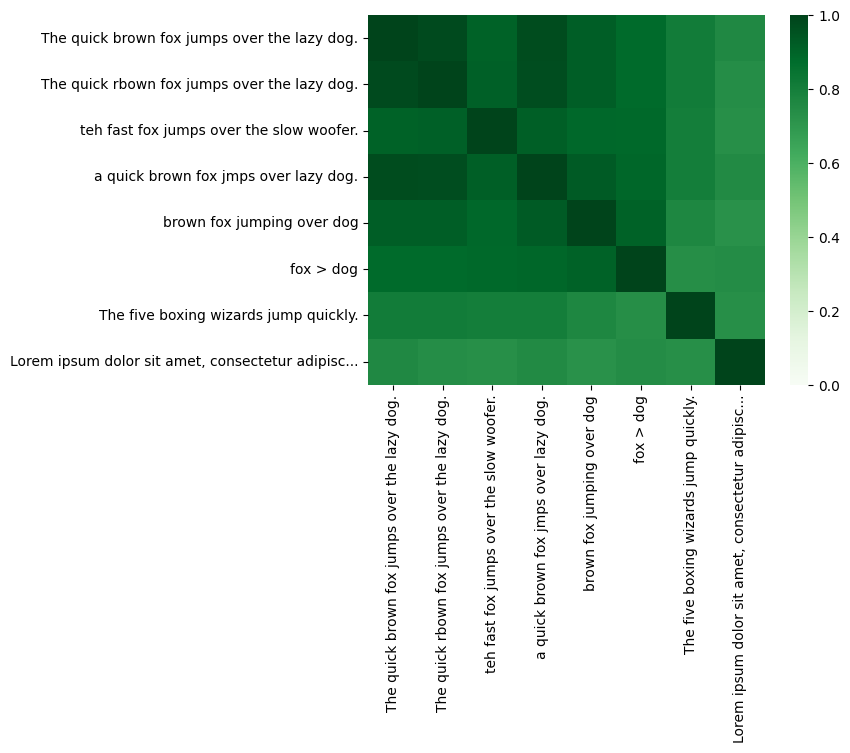

In [ ]:
import pandas as pd
import seaborn as sns

# 1) Extraction des valeurs vectorielles d'embeddings et création d'un DataFrame indexé par nos textes tronqués
df = pd.DataFrame([e.values for e in response.embeddings], index=truncated_texts)

# 2) Calcul de la similarité cosinus par produit matriciel (les vecteurs étant déjà normalisés de norme 1)
sim = df @ df.T

# 3) Visualisation de la matrice de corrélation sous forme de carte de chaleur (heatmap) avec Seaborn
sns.heatmap(sim, vmin=0, vmax=1, cmap="Greens");

Vous pouvez consulter directement les scores d'un texte en le recherchant dans le dataframe.

In [ ]:
# Analyse ciblée : tri par ordre décroissant des scores de similarité pour la phrase de référence d'origine
sim['The quick brown fox jumps over the lazy dog.'].sort_values(ascending=False)

,The quick brown fox jumps over the lazy dog.
The quick brown fox jumps over the lazy dog.,1.000000
The quick rbown fox jumps over the lazy dog.,0.977811
a quick brown fox jmps over lazy dog.,0.976155
brown fox jumping over dog,0.921726
teh fast fox jumps over the slow woofer.,0.907323
fox > dog,0.882391
The five boxing wizards jump quickly.,0.811250
"Lorem ipsum dolor sit amet, consectetur adipisc...",0.760131


Essayez d'explorer les embeddings de vos propres jeux de données, par exemple des phrases en français, ou comparez une phrase avec sa traduction.

## Pour aller plus loin

* Découvrez le [reclassement (re-ranking) de résultats de recherche avec des embeddings](https://github.com/google-gemini/cookbook/blob/main/examples/Search_reranking_using_embeddings.ipynb), avec l'API Wikipédia
* Faites de la [détection d'anomalies avec des embeddings](https://github.com/google-gemini/cookbook/blob/main/examples/Anomaly_detection_with_embeddings.ipynb)
